# 🎬 Die Evolution des Kinos — Teil 1: Datenpipeline

**Ziel:** Ein Filmdatensatz von 1920 bis 2026 mit Finanzdaten, als Grundlage für das Prognosemodell (Teil 2) und das Dashboard (`app.py`).

| Schritt | Quelle | Inhalt |
|---|---|---|
| 1 | Kaggle *The Movies Dataset* | ~45.000 Filme bis 2017 |
| 2 | TMDb API | Top-200 Filme pro Jahr, 2018–2025, inkl. Budget & Einnahmen |
| 3 | Manuell | 6 erwartete Blockbuster für 2026 |
| 4 | Academy Awards | Gewinner „Bester Film“ als Feature |

**Benötigt:** einen TMDb API-Key und einen Kaggle API-Token (siehe README).

In [ ]:
# Nur nötig in Colab — lokal: pip install -r requirements-notebooks.txt
%pip install -q kaggle tqdm

In [ ]:
# ── Setup: läuft in Google Colab UND lokal ───────────────────────────────────
import os, sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

# Projektordner: lokal = Repo-Root (auch wenn aus notebooks/ gestartet), Colab = /content
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR  = ROOT / "data"
MODEL_DIR = ROOT / "models"
IMG_DIR   = ROOT / "images"
RAW_DIR   = ROOT / "kaggle_data"          # Rohdaten von Kaggle (nicht im Repo)
for d in (DATA_DIR, MODEL_DIR, IMG_DIR, RAW_DIR):
    d.mkdir(parents=True, exist_ok=True)

def get_secret(name):
    """Colab: aus Colab Secrets (🔑 links). Lokal: aus Umgebungsvariable / .env."""
    if IN_COLAB:
        try:
            from google.colab import userdata
            return userdata.get(name)
        except Exception:
            pass
    return os.environ.get(name)

print(f"{'Colab' if IN_COLAB else 'Lokal'} | Projektordner: {ROOT}")

Colab | Projektordner: /content


In [ ]:
import json
import time
import requests
import numpy as np
import pandas as pd
from tqdm import tqdm
from ast import literal_eval
from datetime import datetime

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)
print("✅ All imports successful")

✅ All imports successful


## TMDb API aufrufen

In [ ]:
TMDB_API_KEY = get_secret("TMDB_API_KEY")
TMDB_BASE    = "https://api.themoviedb.org/3"
assert TMDB_API_KEY, "TMDB_API_KEY fehlt — in Colab Secrets oder als Umgebungsvariable setzen (siehe README)."

r = requests.get(f"{TMDB_BASE}/configuration", params={"api_key": TMDB_API_KEY})
if r.status_code == 200:
    print("✅ TMDb API key is valid")
else:
    print(f" TMDb error {r.status_code} – check your key")

✅ TMDb API key is valid


## Mit Kaggle verbinden und Datensatz runterladen

Dataset: **The Movies Dataset** von Rounak Banik
~45,000 Filme mit Metadaten, credits, keywords, ratings (bis ~2017)

In [ ]:
# Kaggle-Login: Colab Secrets / Umgebungsvariablen KAGGLE_USERNAME + KAGGLE_KEY,
# oder eine kaggle.json in ~/.kaggle/ bzw. ~/.config/kaggle/ (wird NIE ins Repo committet).
for var in ("KAGGLE_USERNAME", "KAGGLE_KEY"):
    val = get_secret(var)
    if val:
        os.environ[var] = val

has_token_file = any(p.exists() for p in [Path.home()/".kaggle/kaggle.json",
                                           Path.home()/".config/kaggle/kaggle.json"])
if IN_COLAB and not os.environ.get("KAGGLE_KEY") and not has_token_file:
    from google.colab import files
    print("Keine Kaggle-Secrets gefunden — bitte kaggle.json hochladen…")
    files.upload()
    target = Path.home() / ".config/kaggle/kaggle.json"
    target.parent.mkdir(parents=True, exist_ok=True)
    os.replace("kaggle.json", target)
    os.chmod(target, 0o600)
    print("✅ kaggle.json placed correctly")

Keine Kaggle-Secrets gefunden — bitte kaggle.json hochladen…


Saving kaggle.json to kaggle.json
✅ kaggle.json placed correctly


In [ ]:
if not (RAW_DIR / "movies_metadata.csv").exists():
    !kaggle datasets download -d rounakbanik/the-movies-dataset --unzip -p "{RAW_DIR}"
else:
    print("Kaggle-Daten bereits vorhanden — Download übersprungen.")

for f in sorted(os.listdir(RAW_DIR)):
    size = os.path.getsize(RAW_DIR / f) / 1024
    print(f"  {f}  ({size:.0f} KB)")

Dataset URL: https://www.kaggle.com/datasets/rounakbanik/the-movies-dataset
License(s): CC0-1.0
100% 228M/228M [00:01<00:00, 122MB/s]

  credits.csv  (185466 KB)
  keywords.csv  (6086 KB)
  links.csv  (966 KB)
  links_small.csv  (179 KB)
  movies_metadata.csv  (33638 KB)
  ratings.csv  (692920 KB)
  ratings_small.csv  (2381 KB)


In [ ]:
movies_raw = pd.read_csv(RAW_DIR / "movies_metadata.csv", low_memory=False)
print(f"Shape: {movies_raw.shape}")
movies_raw.head(3)

Shape: (45466, 24)


,adult,belongs_to_collection,budget,genres,homepage,id,imdb_id,original_language,original_title,overview,popularity,poster_path,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,video,vote_average,vote_count
0,False,"{'id': 10194, 'name': 'Toy Story Collection', ...",30000000,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...",http://toystory.disney.com/toy-story,862,tt0114709,en,Toy Story,"Led by Woody, Andy's toys live happily in his ...",21.946943,/rhIRbceoE9lR4veEXuwCC2wARtG.jpg,"[{'name': 'Pixar Animation Studios', 'id': 3}]","[{'iso_3166_1': 'US', 'name': 'United States o...",1995-10-30,"373,554,033.00",81.00,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,NaN,Toy Story,False,7.70,"5,415.00"
1,False,NaN,65000000,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",NaN,8844,tt0113497,en,Jumanji,When siblings Judy and Peter discover an encha...,17.015539,/vzmL6fP7aPKNKPRTFnZmiUfciyV.jpg,"[{'name': 'TriStar Pictures', 'id': 559}, {'na...","[{'iso_3166_1': 'US', 'name': 'United States o...",1995-12-15,"262,797,249.00",104.00,"[{'iso_639_1': 'en', 'name': 'English'}, {'iso...",Released,Roll the dice and unleash the excitement!,Jumanji,False,6.90,"2,413.00"
2,False,"{'id': 119050, 'name': 'Grumpy Old Men Collect...",0,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ...",NaN,15602,tt0113228,en,Grumpier Old Men,A family wedding reignites the ancient feud be...,11.7129,/6ksm1sjKMFLbO7UY2i6G1ju9SML.jpg,"[{'name': 'Warner Bros.', 'id': 6194}, {'name'...","[{'iso_3166_1': 'US', 'name': 'United States o...",1995-12-22,0.00,101.00,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Still Yelling. Still Fighting. Still Ready for...,Grumpier Old Men,False,6.50,92.00


## Datensatz bereinigen

In [ ]:
df = movies_raw.copy()

# ── 4.1  Drop clearly irrelevant / mostly-empty columns ─────────────────────
drop_cols = ['belongs_to_collection', 'homepage', 'imdb_id',
             'original_title', 'overview', 'poster_path',
             'spoken_languages', 'status', 'tagline', 'video']
df.drop(columns=[c for c in drop_cols if c in df.columns], inplace=True)

# ── 4.2  Fix data types ─────────────────────────────────────────────────────
df['id'] = pd.to_numeric(df['id'], errors='coerce')
df.dropna(subset=['id'], inplace=True)
df['id'] = df['id'].astype(int)

df['budget']    = pd.to_numeric(df['budget'],    errors='coerce').fillna(0)
df['revenue']   = pd.to_numeric(df['revenue'],   errors='coerce').fillna(0)
df['runtime']   = pd.to_numeric(df['runtime'],   errors='coerce')
df['vote_count']= pd.to_numeric(df['vote_count'],errors='coerce').fillna(0)
df['vote_average']= pd.to_numeric(df['vote_average'],errors='coerce')
df['popularity']= pd.to_numeric(df['popularity'],errors='coerce')

# ── 4.3  Parse release_date → year, month ───────────────────────────────────
df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')
df['release_year']  = df['release_date'].dt.year
df['release_month'] = df['release_date'].dt.month
df.dropna(subset=['release_year'], inplace=True)
df['release_year'] = df['release_year'].astype(int)

# ── 4.4  Filter sensible year range ─────────────────────────────────────────
df = df[(df['release_year'] >= 1920) & (df['release_year'] <= 2017)].copy()

# ── 4.5  Parse genres (stored as JSON string) ────────────────────────────────
def parse_json_list(val, key='name'):
    try:
        items = literal_eval(val)
        return [i[key] for i in items if key in i]
    except Exception:
        return []

df['genres_list'] = df['genres'].apply(parse_json_list)
df['primary_genre'] = df['genres_list'].apply(lambda x: x[0] if x else 'Unknown')
df['genres_str']    = df['genres_list'].apply(lambda x: '|'.join(x))

# ── 4.6  Parse production_countries ─────────────────────────────────────────
df['countries_list']   = df['production_countries'].apply(
    lambda x: parse_json_list(x, key='name'))
df['primary_country']  = df['countries_list'].apply(lambda x: x[0] if x else 'Unknown')

# ── 4.7  Parse production_companies ─────────────────────────────────────────
df['companies_list']  = df['production_companies'].apply(parse_json_list)
df['primary_company'] = df['companies_list'].apply(lambda x: x[0] if x else 'Unknown')

# ── 4.8  Flag rows with usable financial data (for the modelling subset) ─────
df['has_financials'] = (df['budget'] > 10_000) & (df['revenue'] > 10_000)

# ── 4.9  Decade column ───────────────────────────────────────────────────────
df['decade'] = (df['release_year'] // 10 * 10).astype(str) + 's'

# ── 4.10 Drop helper columns ────────────────────────────────────────────────
df.drop(columns=['genres', 'production_countries', 'production_companies'], inplace=True)

print(f"✅ Cleaned Kaggle dataset: {df.shape}")
df.dtypes

✅ Cleaned Kaggle dataset: (45026, 22)


,0
adult,object
budget,int64
id,int64
original_language,object
popularity,float64
release_date,datetime64[ns]
revenue,float64
runtime,float64
title,object
vote_average,float64


## Oscar-Gewinner (Bester Film)

Liste aller Gewinner des Academy Award für den **Besten Film**, mit dem Kinostart-Jahr des Films (nicht dem Jahr der Verleihung).
Quelle: Academy of Motion Picture Arts and Sciences ([oscars.org](https://www.oscars.org/oscars/ceremonies)).

Der Abgleich erfolgt über den normalisierten Titel und ±1 Jahr Toleranz, da Datenbanken teils das Premierendatum statt des Kinostarts speichern.

In [ ]:
OSCAR_BEST_PICTURE = [
    # (Titel, Erscheinungsjahr, alternative Titel in TMDb/Kaggle)
    ("Wings", 1927, []), ("The Broadway Melody", 1929, []),
    ("All Quiet on the Western Front", 1930, []), ("Cimarron", 1931, []),
    ("Grand Hotel", 1932, []), ("Cavalcade", 1933, []),
    ("It Happened One Night", 1934, []), ("Mutiny on the Bounty", 1935, []),
    ("The Great Ziegfeld", 1936, []), ("The Life of Emile Zola", 1937, []),
    ("You Can't Take It with You", 1938, []), ("Gone with the Wind", 1939, []),
    ("Rebecca", 1940, []), ("How Green Was My Valley", 1941, []),
    ("Mrs. Miniver", 1942, []), ("Casablanca", 1942, []),
    ("Going My Way", 1944, []), ("The Lost Weekend", 1945, []),
    ("The Best Years of Our Lives", 1946, []), ("Gentleman's Agreement", 1947, []),
    ("Hamlet", 1948, []), ("All the King's Men", 1949, []),
    ("All About Eve", 1950, []), ("An American in Paris", 1951, []),
    ("The Greatest Show on Earth", 1952, []), ("From Here to Eternity", 1953, []),
    ("On the Waterfront", 1954, []), ("Marty", 1955, []),
    ("Around the World in 80 Days", 1956, ["Around the World in Eighty Days"]),
    ("The Bridge on the River Kwai", 1957, []), ("Gigi", 1958, []),
    ("Ben-Hur", 1959, []), ("The Apartment", 1960, []),
    ("West Side Story", 1961, []), ("Lawrence of Arabia", 1962, []),
    ("Tom Jones", 1963, []), ("My Fair Lady", 1964, []),
    ("The Sound of Music", 1965, []), ("A Man for All Seasons", 1966, []),
    ("In the Heat of the Night", 1967, []), ("Oliver!", 1968, []),
    ("Midnight Cowboy", 1969, []), ("Patton", 1970, []),
    ("The French Connection", 1971, []), ("The Godfather", 1972, []),
    ("The Sting", 1973, []), ("The Godfather: Part II", 1974, []),
    ("One Flew Over the Cuckoo's Nest", 1975, []), ("Rocky", 1976, []),
    ("Annie Hall", 1977, []), ("The Deer Hunter", 1978, []),
    ("Kramer vs. Kramer", 1979, []), ("Ordinary People", 1980, []),
    ("Chariots of Fire", 1981, []), ("Gandhi", 1982, []),
    ("Terms of Endearment", 1983, []), ("Amadeus", 1984, []),
    ("Out of Africa", 1985, []), ("Platoon", 1986, []),
    ("The Last Emperor", 1987, []), ("Rain Man", 1988, []),
    ("Driving Miss Daisy", 1989, []), ("Dances with Wolves", 1990, []),
    ("The Silence of the Lambs", 1991, []), ("Unforgiven", 1992, []),
    ("Schindler's List", 1993, []), ("Forrest Gump", 1994, []),
    ("Braveheart", 1995, []), ("The English Patient", 1996, []),
    ("Titanic", 1997, []), ("Shakespeare in Love", 1998, []),
    ("American Beauty", 1999, []), ("Gladiator", 2000, []),
    ("A Beautiful Mind", 2001, []), ("Chicago", 2002, []),
    ("The Lord of the Rings: The Return of the King", 2003, []),
    ("Million Dollar Baby", 2004, []), ("Crash", 2004, []),
    ("The Departed", 2006, []), ("No Country for Old Men", 2007, []),
    ("Slumdog Millionaire", 2008, []), ("The Hurt Locker", 2008, []),
    ("The King's Speech", 2010, []), ("The Artist", 2011, []),
    ("Argo", 2012, []), ("12 Years a Slave", 2013, []),
    ("Birdman", 2014, ["Birdman or (The Unexpected Virtue of Ignorance)"]),
    ("Spotlight", 2015, []), ("Moonlight", 2016, []),
    ("The Shape of Water", 2017, []), ("Green Book", 2018, []),
    ("Parasite", 2019, []), ("Nomadland", 2020, []), ("CODA", 2021, []),
    ("Everything Everywhere All at Once", 2022, []), ("Oppenheimer", 2023, []),
    ("Anora", 2024, []), ("One Battle After Another", 2025, []),
]

import re
def norm_title(t):
    return re.sub(r"[^a-z0-9]+", " ", str(t).lower()).strip()

oscar_df = pd.DataFrame(
    [(t, y) for t, y, _ in OSCAR_BEST_PICTURE], columns=["title", "release_year"]
)
OSCAR_LOOKUP = {}
for t, y, alts in OSCAR_BEST_PICTURE:
    for name in [t, *alts]:
        OSCAR_LOOKUP.setdefault(norm_title(name), []).append(y)

def flag_oscar_winners(frame):
    """True, wenn Titel übereinstimmt und das Jahr maximal 1 Jahr abweicht."""
    return pd.Series([
        any(abs(int(y) - oy) <= 1 for oy in OSCAR_LOOKUP.get(norm_title(t), []))
        for t, y in zip(frame["title"], frame["release_year"])
    ], index=frame.index)

df['is_oscar_winner'] = flag_oscar_winners(df)
print(f"✅ {len(oscar_df)} Best-Picture-Gewinner | davon im Kaggle-Datensatz gefunden: {df['is_oscar_winner'].sum()}")

✅ 98 Best-Picture-Gewinner | davon im Kaggle-Datensatz gefunden: 90


## Kaggle Datensatz mit TMDb erweitern (2018 - 2025)

In [ ]:
# ── 6.1  Fetch TMDb genre map ────────────────────────────────────────────────
def tmdb_get(endpoint, params=None, retries=3):
    """Helper: GET from TMDb with error handling & rate-limit respect."""
    params = dict(params or {})          # copy — never mutate a shared default
    params['api_key'] = TMDB_API_KEY
    for attempt in range(retries):
        try:
            r = requests.get(f"{TMDB_BASE}/{endpoint}", params=params, timeout=20)
        except requests.RequestException:
            time.sleep(2)
            continue
        if r.status_code == 429:         # rate limited
            time.sleep(10)
            continue
        if r.status_code != 200:
            return None
        return r.json()
    return None

genre_data = tmdb_get("genre/movie/list")
GENRE_MAP  = {g['id']: g['name'] for g in genre_data['genres']}
print("Genre map:", GENRE_MAP)

Genre map: {28: 'Action', 12: 'Adventure', 16: 'Animation', 35: 'Comedy', 80: 'Crime', 99: 'Documentary', 18: 'Drama', 10751: 'Family', 14: 'Fantasy', 36: 'History', 27: 'Horror', 10402: 'Music', 9648: 'Mystery', 10749: 'Romance', 878: 'Science Fiction', 10770: 'TV Movie', 53: 'Thriller', 10752: 'War', 37: 'Western'}


## 200 beliebteste Filme von 2018 bis 2025 extrahieren

In [ ]:
# ── 6.2  Discover movies 2018-2025 (top 200 per year by popularity) ──────────
def fetch_year(year, pages=10):
    """Fetch `pages` pages of popular movies for a given year."""
    results = []
    for page in range(1, pages + 1):
        data = tmdb_get("discover/movie", {
            'primary_release_year': year,
            'sort_by': 'popularity.desc',
            'page': page,
            'language': 'en-US'
        })
        if data and 'results' in data:
            results.extend(data['results'])
        time.sleep(0.25)  # stay within TMDb rate limits
    return results

tmdb_records = []
for year in tqdm(range(2018, 2026), desc="Fetching years"):
    tmdb_records.extend(fetch_year(year, pages=10))

print(f"\n✅ Fetched {len(tmdb_records)} raw TMDb records (2018-2025)")

Fetching years: 100%|██████████| 8/8 [00:25<00:00,  3.17s/it]


✅ Fetched 1600 raw TMDb records (2018-2025)


In [ ]:
# ── 6.3  Fetch detailed financials for each movie (budget + revenue) ─────────
# TMDb's discover endpoint doesn't include budget/revenue – need individual calls

def fetch_details(movie_id):
    return tmdb_get(f"movie/{movie_id}")

unique_ids = list({m['id'] for m in tmdb_records})
print(f"Fetching details for {len(unique_ids)} unique movies… (ca. 10 Minuten)")

details_map = {}
for mid in tqdm(unique_ids, desc="Movie details"):
    d = fetch_details(mid)
    if d:
        details_map[mid] = d
    time.sleep(0.25)

print(f"✅ Fetched details for {len(details_map)} movies")

Fetching details for 1597 unique movies… (ca. 10 Minuten)


Movie details: 100%|██████████| 1597/1597 [09:33<00:00,  2.79it/s]

✅ Fetched details for 1597 movies


In [ ]:
# ── 6.4  Build normalised TMDb DataFrame ─────────────────────────────────────
rows = []
for mid, d in details_map.items():
    genres_list  = [g['name'] for g in d.get('genres', [])]
    countries    = [c['name'] for c in d.get('production_countries', [])]
    companies    = [c['name'] for c in d.get('production_companies', [])]
    release_date = pd.to_datetime(d.get('release_date'), errors='coerce')

    rows.append({
        'id':              mid,
        'title':           d.get('title', ''),
        'release_date':    release_date,
        'release_year':    release_date.year if pd.notna(release_date) else None,
        'release_month':   release_date.month if pd.notna(release_date) else None,
        'budget':          d.get('budget', 0) or 0,
        'revenue':         d.get('revenue', 0) or 0,
        'runtime':         d.get('runtime'),
        'vote_average':    d.get('vote_average'),
        'vote_count':      d.get('vote_count', 0),
        'popularity':      d.get('popularity'),
        'original_language': d.get('original_language'),
        'genres_list':     genres_list,
        'primary_genre':   genres_list[0] if genres_list else 'Unknown',
        'genres_str':      '|'.join(genres_list),
        'countries_list':  countries,
        'primary_country': countries[0] if countries else 'Unknown',
        'companies_list':  companies,
        'primary_company': companies[0] if companies else 'Unknown',
        'adult':           d.get('adult', False),
        'source':          'tmdb'
    })

tmdb_df = pd.DataFrame(rows)
tmdb_df.dropna(subset=['release_year'], inplace=True)
tmdb_df['release_year'] = tmdb_df['release_year'].astype(int)
tmdb_df['has_financials'] = (tmdb_df['budget'] > 10_000) & (tmdb_df['revenue'] > 10_000)
tmdb_df['decade'] = (tmdb_df['release_year'] // 10 * 10).astype(str) + 's'

# Oscar flags for recent winners
tmdb_df['is_oscar_winner'] = flag_oscar_winners(tmdb_df)

print(f"✅ TMDb DataFrame: {tmdb_df.shape} | Oscar-Gewinner: {tmdb_df['is_oscar_winner'].sum()}")
tmdb_df.head(3)

✅ TMDb DataFrame: (1597, 24) | Oscar-Gewinner: 8


,id,title,release_date,release_year,release_month,budget,revenue,runtime,vote_average,vote_count,popularity,original_language,genres_list,primary_genre,genres_str,countries_list,primary_country,companies_list,primary_company,adult,source,has_financials,decade,is_oscar_winner
0,663558,New Gods: Nezha Reborn,2021-02-06,2021,2,0,70000000,117,8.05,541,3.51,zh,"[Animation, Fantasy, Action]",Animation,Animation|Fantasy|Action,[China],China,"[bilibili, Alibaba Pictures Group, Light Chase...",bilibili,False,tmdb,False,2020s,False
1,614409,To All the Boys: Always and Forever,2021-02-12,2021,2,0,0,114,7.49,2107,3.97,en,"[Romance, Comedy, Drama]",Romance,Romance|Comedy|Drama,[United States of America],United States of America,"[Awesomeness Films, ACE Entertainment]",Awesomeness Films,False,tmdb,False,2020s,False
2,581644,The Misfits,2021-06-03,2021,6,0,0,94,5.43,543,3.01,en,"[Action, Thriller]",Action,Action|Thriller,"[Finland, United Arab Emirates, United States ...",Finland,"[Kjam Media, RNG Entertainment, FilmGate Produ...",Kjam Media,False,tmdb,False,2020s,False


## Kommende 2026 Filme addieren

Erwartete Blockbuster mit geschätzten Budgets — diese Filme werden in Teil 2 vom Modell prognostiziert.

In [ ]:
upcoming_2026 = pd.DataFrame([
    # title, budget_est, genres, country, company, release_month, runtime_est
    {"title": "The Odyssey",              "budget": 250_000_000, "primary_genre": "Adventure",
     "genres_str": "Adventure|Drama",     "primary_country": "United States of America",
     "primary_company": "Universal Pictures", "release_month": 7, "runtime": 150,
     "original_language": "en"},
    {"title": "Avatar 3",                  "budget": 350_000_000, "primary_genre": "Science Fiction",
     "genres_str": "Science Fiction|Action|Adventure", "primary_country": "United States of America",
     "primary_company": "20th Century Studios", "release_month": 12, "runtime": 165,
     "original_language": "en"},
    {"title": "Mission: Impossible 8",     "budget": 300_000_000, "primary_genre": "Action",
     "genres_str": "Action|Thriller",      "primary_country": "United States of America",
     "primary_company": "Paramount Pictures", "release_month": 5, "runtime": 145,
     "original_language": "en"},
    {"title": "Jurassic World 4",          "budget": 220_000_000, "primary_genre": "Science Fiction",
     "genres_str": "Science Fiction|Action|Adventure", "primary_country": "United States of America",
     "primary_company": "Universal Pictures", "release_month": 7, "runtime": 130,
     "original_language": "en"},
    {"title": "Sinners",                   "budget": 90_000_000,  "primary_genre": "Horror",
     "genres_str": "Horror|Thriller",      "primary_country": "United States of America",
     "primary_company": "Warner Bros.",    "release_month": 4, "runtime": 120,
     "original_language": "en"},
    {"title": "Superman (2026)",           "budget": 200_000_000, "primary_genre": "Action",
     "genres_str": "Action|Science Fiction", "primary_country": "United States of America",
     "primary_company": "Warner Bros.",    "release_month": 7, "runtime": 140,
     "original_language": "en"},
])

upcoming_2026['release_year']    = 2026
upcoming_2026['revenue']         = 0
upcoming_2026['vote_average']    = np.nan
upcoming_2026['vote_count']      = 0
upcoming_2026['popularity']      = np.nan
upcoming_2026['is_oscar_winner'] = False
upcoming_2026['has_financials']  = False
upcoming_2026['decade']          = '2020s'
upcoming_2026['source']          = 'manual_2026'
upcoming_2026['adult']           = False
upcoming_2026['countries_list']  = upcoming_2026['primary_country'].apply(lambda x: [x])
upcoming_2026['companies_list']  = upcoming_2026['primary_company'].apply(lambda x: [x])
upcoming_2026['genres_list']     = upcoming_2026['genres_str'].apply(lambda x: x.split('|'))

print(f"✅ {len(upcoming_2026)} upcoming 2026 movies added")
upcoming_2026[['title','budget','primary_genre','release_month']]

✅ 6 upcoming 2026 movies added


,title,budget,primary_genre,release_month
0,The Odyssey,250000000,Adventure,7
1,Avatar 3,350000000,Science Fiction,12
2,Mission: Impossible 8,300000000,Action,5
3,Jurassic World 4,220000000,Science Fiction,7
4,Sinners,90000000,Horror,4
5,Superman (2026),200000000,Action,7


## Datensätze mergen

In [ ]:
df['source'] = 'kaggle'
if 'adult' not in df.columns:
    df['adult'] = False

shared_cols = [
    'title', 'release_year', 'release_month', 'budget', 'revenue',
    'runtime', 'vote_average', 'vote_count', 'popularity',
    'original_language', 'primary_genre', 'genres_str', 'genres_list',
    'primary_country', 'countries_list', 'primary_company', 'companies_list',
    'is_oscar_winner', 'has_financials', 'decade', 'source', 'adult'
]

full_df = pd.concat(
    [df[shared_cols], tmdb_df[shared_cols], upcoming_2026[shared_cols]],
    ignore_index=True
)
full_df['is_oscar_winner'] = full_df['is_oscar_winner'].fillna(False).astype(bool)

# Deduplicate: keep TMDb version for 2018+ overlaps (more recent/accurate)
full_df.sort_values('source', ascending=False, inplace=True)  # tmdb > manual > kaggle
full_df.drop_duplicates(subset=['title', 'release_year'], keep='first', inplace=True)
full_df.sort_values(['release_year', 'title'], inplace=True)
full_df.reset_index(drop=True, inplace=True)

print(f"✅ Full merged dataset: {full_df.shape}")
print(f"   Years: {full_df['release_year'].min()} – {full_df['release_year'].max()}")
print(f"   Oscar winners: {full_df['is_oscar_winner'].sum()}")
print(f"   Rows with financials: {full_df['has_financials'].sum()}")
full_df.head(3)

✅ Full merged dataset: (46548, 22)
   Years: 1920 – 2026
   Oscar winners: 98
   Rows with financials: 6139


,title,release_year,release_month,budget,revenue,runtime,vote_average,vote_count,popularity,original_language,primary_genre,genres_str,genres_list,primary_country,countries_list,primary_company,companies_list,is_oscar_winner,has_financials,decade,source,adult
0,Convict 13,1920,10.00,0,0.00,20.00,6.60,14.00,0.82,fr,Comedy,Comedy,[Comedy],United States of America,[United States of America],Joseph M. Schenck Production,[Joseph M. Schenck Production],False,False,1920s,kaggle,False
1,Dr. Jekyll and Mr. Hyde,1920,3.00,0,0.00,67.00,6.80,26.00,1.56,en,Drama,Drama|Horror|Science Fiction,"[Drama, Horror, Science Fiction]",United States of America,[United States of America],Famous Players-Lasky Corporation,[Famous Players-Lasky Corporation],False,False,1920s,kaggle,False
2,Erotikon,1920,11.00,0,0.00,97.00,5.50,4.00,0.21,sv,Romance,Romance|Drama|Comedy,"[Romance, Drama, Comedy]",Unknown,[],Unknown,[],False,False,1920s,kaggle,False


## Feature Engineering (für ML)

In [ ]:
# ── 9.1  Inflation adjustment (convert all budgets/revenues to 2024 USD) ──────
# Simplified CPI multipliers by decade (approximate)
CPI_MULTIPLIERS = {
    '1920s': 18.0, '1930s': 22.0, '1940s': 16.0, '1950s': 11.0,
    '1960s': 9.5,  '1970s': 6.5,  '1980s': 3.5,  '1990s': 2.1,
    '2000s': 1.65, '2010s': 1.25, '2020s': 1.05, '2030s': 1.0
}

full_df['cpi_mult']          = full_df['decade'].map(CPI_MULTIPLIERS).fillna(1.0)
full_df['budget_adj']        = full_df['budget']  * full_df['cpi_mult']
full_df['revenue_adj']       = full_df['revenue'] * full_df['cpi_mult']

# ── 9.2  ROI ─────────────────────────────────────────────────────────────────
full_df['roi'] = np.where(
    full_df['budget_adj'] > 0,
    (full_df['revenue_adj'] - full_df['budget_adj']) / full_df['budget_adj'].where(full_df['budget_adj'] > 0),
    np.nan
)

# ── 9.3  Is it a summer/holiday release? ─────────────────────────────────────
full_df['is_summer']  = full_df['release_month'].isin([5, 6, 7, 8]).astype(int)
full_df['is_holiday'] = full_df['release_month'].isin([11, 12]).astype(int)

# ── 9.4  Log-transform budget and revenue (for ML) ───────────────────────────
full_df['log_budget']  = np.log1p(full_df['budget_adj'])
full_df['log_revenue'] = np.log1p(full_df['revenue_adj'])

print("✅ Feature engineering complete")
print(full_df[['title','release_year','budget_adj','revenue_adj','roi','is_summer']].head(5))

✅ Feature engineering complete
                     title  release_year  budget_adj  revenue_adj  roi  \
0               Convict 13          1920        0.00         0.00  NaN   
1  Dr. Jekyll and Mr. Hyde          1920        0.00         0.00  NaN   
2                 Erotikon          1920        0.00         0.00  NaN   
3    From Morn to Midnight          1920        0.00         0.00  NaN   
4           High and Dizzy          1920        0.00         0.00  NaN   

   is_summer  
0          0  
1          0  
2          0  
3          0  
4          1  


## CSV exportieren

Alle Dateien landen in `data/` — genau dort sucht das Dashboard (`app.py`) und Teil 2 danach.

In [ ]:
# ── 10.1  Full dataset (for all dashboard charts) ────────────────────────────
full_df.drop(columns=['genres_list', 'countries_list', 'companies_list', 'cpi_mult'], inplace=True)
full_df.to_csv(DATA_DIR / "movies_full.csv", index=False)
print(f"✅ movies_full.csv  → {full_df.shape}")

# ── 10.2  Financial subset (for model training) ───────────────────────────────
fin_df = full_df[
    (full_df['has_financials']) &
    (full_df['source'].isin(['kaggle', 'tmdb'])) &
    (full_df['budget_adj'] > 0)
].copy()
fin_df.to_csv(DATA_DIR / "movies_financials.csv", index=False)
print(f"✅ movies_financials.csv → {fin_df.shape}")

# ── 10.3  Upcoming 2026 movies (for prediction UI) ───────────────────────────
upcoming_export = full_df[full_df['source'] == 'manual_2026'].copy()
upcoming_export.to_csv(DATA_DIR / "movies_2026_upcoming.csv", index=False)
print(f"✅ movies_2026_upcoming.csv → {upcoming_export.shape}")

# ── 10.4  Genre trend data per YEAR (lighter file for the genre chart) ────────
genre_trend = (
    full_df[
        (full_df["primary_genre"] != "Unknown") &
        (full_df["release_year"] >= 1960) &
        (full_df["release_year"] <= 2025)
    ]
    .groupby(["release_year", "primary_genre"])
    .size()
    .reset_index(name="count")
)
genre_trend.to_csv(DATA_DIR / "genre_trends.csv", index=False)
print(f"✅ genre_trends.csv → {genre_trend.shape}")

print(f"\n📁 All files saved to {DATA_DIR}")

✅ movies_full.csv  → (46548, 26)
✅ movies_financials.csv → (6139, 26)
✅ movies_2026_upcoming.csv → (6, 26)
✅ genre_trends.csv → (1249, 3)

📁 All files saved to /content/data


## EDA

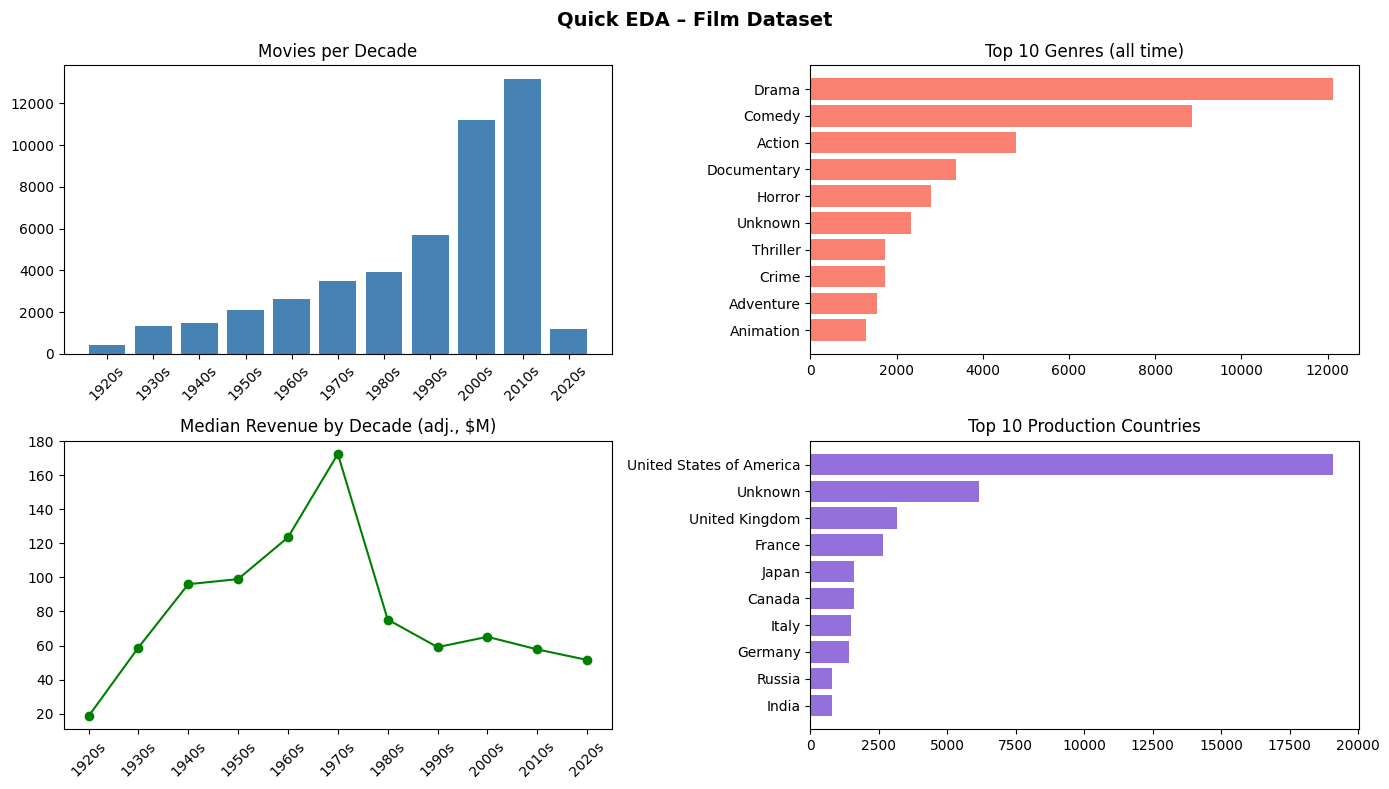

✅ EDA plot saved


In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
fig.suptitle('Quick EDA – Film Dataset', fontsize=14, fontweight='bold')

# Plot 1: Movies per decade
decade_counts = full_df.groupby('decade').size().sort_index()
axes[0,0].bar(decade_counts.index, decade_counts.values, color='steelblue')
axes[0,0].set_title('Movies per Decade')
axes[0,0].tick_params(axis='x', rotation=45)

# Plot 2: Top 10 genres
top_genres = full_df['primary_genre'].value_counts().head(10)
axes[0,1].barh(top_genres.index[::-1], top_genres.values[::-1], color='salmon')
axes[0,1].set_title('Top 10 Genres (all time)')

# Plot 3: Median inflation-adjusted revenue by decade
rev_decade = fin_df.groupby('decade')['revenue_adj'].median().sort_index()
axes[1,0].plot(rev_decade.index, rev_decade.values / 1e6, marker='o', color='green')
axes[1,0].set_title('Median Revenue by Decade (adj., $M)')
axes[1,0].tick_params(axis='x', rotation=45)

# Plot 4: Top 10 production countries
top_countries = full_df['primary_country'].value_counts().head(10)
axes[1,1].barh(top_countries.index[::-1], top_countries.values[::-1], color='mediumpurple')
axes[1,1].set_title('Top 10 Production Countries')

plt.tight_layout()
plt.savefig(IMG_DIR / "eda_preview.png", dpi=150)
plt.show()
print("✅ EDA plot saved")

In [ ]:
# Sanity check: Filme pro Jahr (die letzten 20 Jahre)
print(full_df["release_year"].value_counts().sort_index().tail(20))
print(f"\nMax year: {full_df['release_year'].max()}")

release_year
2007    1318
2008    1468
2009    1583
2010    1500
2011    1661
2012    1717
2013    1884
2014    1967
2015    1899
2016    1601
2017     532
2018     200
2019     200
2020     200
2021     197
2022     200
2023     200
2024     200
2025     200
2026       6
Name: count, dtype: int64

Max year: 2026


## Ergebnisse herunterladen (nur Colab)

Lädt `data/` und `images/` als ZIP herunter. Weiter geht's mit **Teil 2** (`02_revenue_model.ipynb`).

In [ ]:
if IN_COLAB:
    import shutil
    from google.colab import files
    shutil.make_archive("/content/teil1_output", "zip", ROOT, "data")
    shutil.make_archive("/content/teil1_images", "zip", ROOT, "images")
    files.download("/content/teil1_output.zip")
    files.download("/content/teil1_images.zip")
else:
    print(f"Lokal: Dateien liegen bereits in {DATA_DIR}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>